In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra
using JLD2

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))


LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-0.005204183397363345 - 0.0006533914866046188im 0.0021867748363471337 + 0.002611715599938104im … 0.001848280433179565 - 0.005330108136287202im -0.0016751514895533778 + 0.003449544097190184im; 0.0033664594757157234 - 0.0011428499165216908im 0.0005661352744583717 - 0.002620962211671071im … -0.003697600759567385 - 0.000540906344497541im -0.0016926781850123333 - 9.267728382154897e-5im; 0.0014979632353200546 - 0.0010472858158591192im -0.0003417431892000645 - 0.0010060317483520965im … -0.0012699493527918244 + 0.0022096976732595757im 0.0036257862291681742 - 0.00022187283642682937im;;; -0.0028361637601880645 - 0.005019822015396376im 0.0009214493309621481 + 6.802012863286451e-5im … -0.0014830349414288832 + 0.0008922327541472913im 0.0017780568171225112 + 0.002445011710709113im; 0.0015444082587404775 - 0.0014105629372527361im -0.0017276216176047635 - 0.0033917197733301574im … -0.0005547185389307905 - 0.0006971217182133898

In [3]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.1

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[9.183340317907333e-6 + 6.314508607190911e-6im -5.663276823018761e-7 + 8.88386119101705e-7im … -3.6342534073759214e-6 - 2.38679417968451e-6im -1.268682786946639e-6 + 2.693256176879587e-6im; -3.088080956369992e-6 + 2.6748982587825986e-6im -3.2470013856376954e-6 - 2.1309228713362567e-6im … 8.580576102863195e-6 + 9.859880947859032e-6im 2.477422086273955e-6 - 4.247529739960479e-6im; 5.169138333753534e-6 - 7.1657359406204205e-6im -4.3510172288034387e-7 + 8.91292140618977e-6im … 5.494136280566751e-6 - 8.910751509589573e-7im 1.97985544293645e-7 + 1.8185942475344058e-6im;;; 1.0474503338606206e-5 - 2.321887077717704e-7im -8.681585050152743e-7 - 2.538224005746145e-6im … 5.950126427631926e-6 + 1.1901661696361613e-5im -1.482875174077994e-6 + 6.56024208823203e-6im; 5.2818129603831016e-6 + 1.0609542954705863e-5im 3.8347301684106925e-6 + 3.487529259532427e-7im … -9.713834056350102e-7 - 3.131589937240962e-6im -2.517937057025449

In [4]:
P=Onestep()
hop=Hopping_operator(U,P)
W=Generate_weight(hop)


9-element Vector{Spin_matrix}:
 [0.6979233579175335 + 0.0im -0.6036331034114466 + 0.0im 0.3354991828467293 + 0.0im 0.7132995738714333 + 0.0im; -0.1312117749397109 + 0.0im 0.2577071285069425 + 0.0im 0.8607665296461074 + 0.0im -0.28719827066326054 + 0.0im; 0.3712761932525005 + 0.0im 0.5053997233920613 + 0.0im 0.16869094808108895 + 0.0im -0.31034333565293604 + 0.0im; 1.483353059749375 + 0.0im -2.0234926801310205 + 0.0im 1.0279324056042778 + 0.0im 0.7356683864593498 + 0.0im]
 [1.2020757052287823 + 0.0im 0.12676496721274902 + 0.0im -0.34398005570344115 + 0.0im -0.265852662916289 + 0.0im; 0.4129100865664307 + 0.0im 0.012700858127046678 + 0.0im 0.20733392643175208 + 0.0im -1.8581479739679667 + 0.0im; -0.305636193220578 + 0.0im -0.7380598947836146 + 0.0im -0.8848633721557168 + 0.0im 1.0923452238811298 + 0.0im; -0.9642568807703532 + 0.0im -0.061816449206330275 + 0.0im 0.12210368247620643 + 0.0im -0.13350683787953807 + 0.0im]
 [-0.19348027655362027 + 0.0im 0.5773158078756133 + 0.0im -0.013719900

In [ ]:
layer=CPTC_Layer(hop,W)
act=Softmax()
Attention=test_Layer(layer,sqrt(length(x)),t,act)
layers=[Attention]

1-element Vector{Attention_Layer}:
 Attention_Layer(CPTC_Layer(Spin_matrix[[0.6979233579175335 + 0.0im -0.6036331034114466 + 0.0im 0.3354991828467293 + 0.0im 0.7132995738714333 + 0.0im; -0.1312117749397109 + 0.0im 0.2577071285069425 + 0.0im 0.8607665296461074 + 0.0im -0.28719827066326054 + 0.0im; 0.3712761932525005 + 0.0im 0.5053997233920613 + 0.0im 0.16869094808108895 + 0.0im -0.31034333565293604 + 0.0im; 1.483353059749375 + 0.0im -2.0234926801310205 + 0.0im 1.0279324056042778 + 0.0im 0.7356683864593498 + 0.0im], [1.2020757052287823 + 0.0im 0.12676496721274902 + 0.0im -0.34398005570344115 + 0.0im -0.265852662916289 + 0.0im; 0.4129100865664307 + 0.0im 0.012700858127046678 + 0.0im 0.20733392643175208 + 0.0im -1.8581479739679667 + 0.0im; -0.305636193220578 + 0.0im -0.7380598947836146 + 0.0im -0.8848633721557168 + 0.0im 1.0923452238811298 + 0.0im; -0.9642568807703532 + 0.0im -0.061816449206330275 + 0.0im 0.12210368247620643 + 0.0im -0.13350683787953807 + 0.0im], [-0.19348027655362027 + 0.

In [6]:
opt=Adam()
opt.α=0.05

0.05

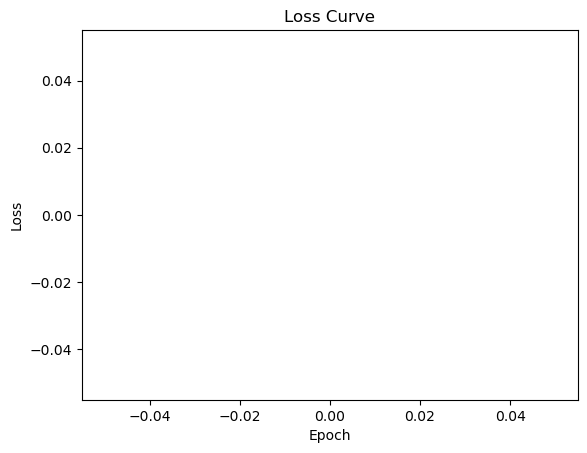

Epoch: 1, Loss: 43.66464668512515 + 0.0im
Epoch: 2, Loss: 38.80147385306146 + 0.0im
Epoch: 3, Loss: 34.15410250846109 + 0.0im
Epoch: 4, Loss: 30.23275619951192 + 0.0im
Epoch: 5, Loss: 26.827891752207506 + 0.0im
Epoch: 6, Loss: 23.84559807312154 + 0.0im
Epoch: 7, Loss: 21.136966117003094 + 0.0im
Epoch: 8, Loss: 18.684739975123765 + 0.0im
Epoch: 9, Loss: 16.1754861124411 + 0.0im
Epoch: 10, Loss: 14.376029028909288 + 0.0im
Epoch: 11, Loss: 12.746148819915692 + 0.0im
Epoch: 12, Loss: 11.223331547259026 + 0.0im
Epoch: 13, Loss: 9.776572190001609 + 0.0im
Epoch: 14, Loss: 8.533379761305772 + 0.0im
Epoch: 15, Loss: 7.5911664739474745 + 0.0im
Epoch: 16, Loss: 6.614745014567781 + 0.0im
Epoch: 17, Loss: 5.736172122325021 + 0.0im
Epoch: 18, Loss: 5.040747479677596 + 0.0im
Epoch: 19, Loss: 4.336292384663722 + 0.0im
Epoch: 20, Loss: 3.8450787283735406 + 0.0im
Epoch: 21, Loss: 3.3894040976733626 + 0.0im
Epoch: 22, Loss: 2.9426941926785037 + 0.0im
Epoch: 23, Loss: 2.6033246215197217 + 0.0im
Epoch: 24,

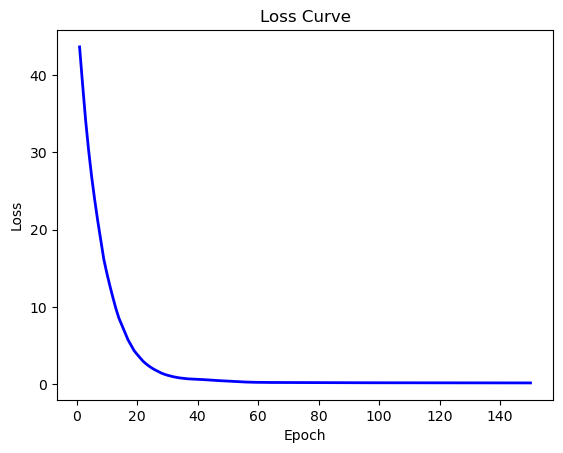

In [7]:
train(opt,layers,x,t,D,epochs=150)


In [ ]:
@save "Attention_weight.jld2" W,